In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
IMG_SIZE = (224, 224)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!


In [ ]:
base_model.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
!pip install -q medmnist

In [ ]:
import medmnist
from medmnist import PneumoniaMNIST

print("MedMNIST version:", medmnist.__version__)

MedMNIST version: 3.0.2


In [ ]:
train_dataset = PneumoniaMNIST(
    split="train",
    size=224,
    download=True
)

val_dataset = PneumoniaMNIST(
    split="val",
    size=224,
    download=True
)

test_dataset = PneumoniaMNIST(
    split="test",
    size=224,
    download=True
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

100%|██████████| 214M/214M [02:01<00:00, 1.77MB/s]


Training images: 4708
Validation images: 524
Testing images: 624


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Get one image and its label
image, label = train_dataset[0]

# Convert PIL image into a NumPy array
image_array = np.array(image)

print("Image shape:", image_array.shape)
print("Label:", label)
print("Image data type:", image_array.dtype)
print("Image minimum:", image_array.min())
print("Image maximum:", image_array.max())

Image shape: (224, 224)
Label: [1]
Image data type: uint8
Image minimum: 0
Image maximum: 241


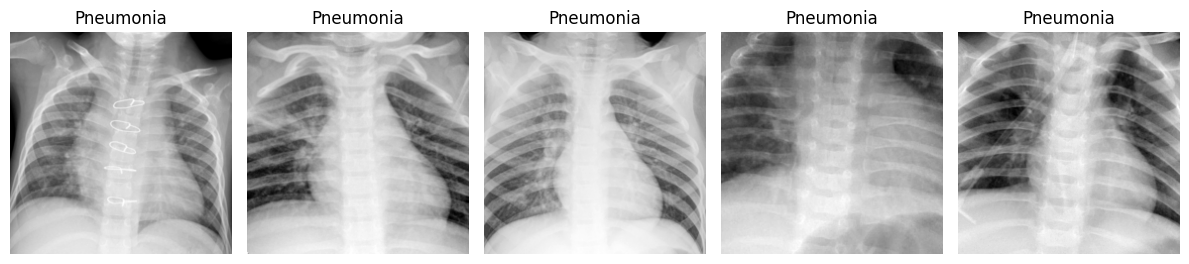

In [ ]:
plt.figure(figsize=(12, 4))

for i in range(5):
    image, label = train_dataset[i]

    plt.subplot(1, 5, i + 1)
    plt.imshow(np.array(image), cmap="gray")
    plt.title("Pneumonia" if int(label[0]) == 1 else "Normal")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from collections import Counter

labels = [int(train_dataset[i][1][0]) for i in range(len(train_dataset))]

label_counts = Counter(labels)

print("Normal images (0):", label_counts[0])
print("Pneumonia images (1):", label_counts[1])

Normal images (0): 1214
Pneumonia images (1): 3494


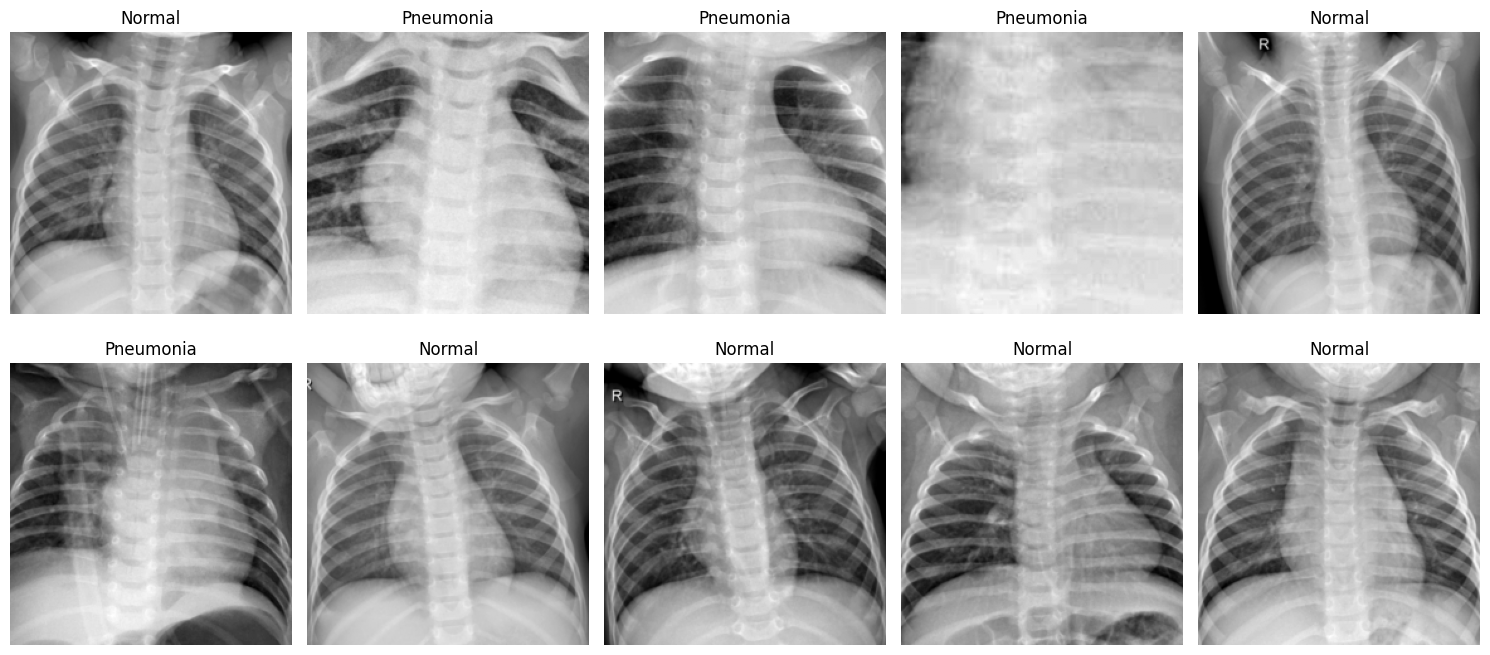

In [ ]:
import random

random_indices = random.sample(range(len(train_dataset)), 10)

plt.figure(figsize=(15, 7))

for position, index in enumerate(random_indices):
    image, label = train_dataset[index]

    plt.subplot(2, 5, position + 1)
    plt.imshow(np.array(image), cmap="gray")
    plt.title("Pneumonia" if int(label[0]) == 1 else "Normal")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def check_distribution(dataset, name):
    labels = [int(dataset[i][1][0]) for i in range(len(dataset))]

    counts = Counter(labels)

    print(f"\n{name}")
    print("Normal:", counts[0])
    print("Pneumonia:", counts[1])

check_distribution(train_dataset, "Training")
check_distribution(val_dataset, "Validation")
check_distribution(test_dataset, "Testing")


Training
Normal: 1214
Pneumonia: 3494

Validation
Normal: 135
Pneumonia: 389

Testing
Normal: 234
Pneumonia: 390


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=labels
)

class_weights = {
    0: class_weights[0],
    1: class_weights[1]
}

print("Class weights:", class_weights)

Class weights: {0: np.float64(1.9390444810543657), 1: np.float64(0.6737263880938752)}


In [ ]:

# Convert images into a format MobileNetV2 understands

def prepare_image(image):
    image = image.convert("RGB")
    image = np.array(image, dtype=np.float32)

    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    return image


def create_generator(dataset):
    for image, label in dataset:
        image = prepare_image(image)
        label = np.float32(label[0])

        yield image, label


# Define the output format
output_signature = (
    tf.TensorSpec(shape=(224, 224, 3), dtype=tf.float32),
    tf.TensorSpec(shape=(), dtype=tf.float32)
)

# Create TensorFlow datasets
train_data = tf.data.Dataset.from_generator(
    lambda: create_generator(train_dataset),
    output_signature=output_signature
)

val_data = tf.data.Dataset.from_generator(
    lambda: create_generator(val_dataset),
    output_signature=output_signature
)

test_data = tf.data.Dataset.from_generator(
    lambda: create_generator(test_dataset),
    output_signature=output_signature
)

# Batch and optimize loading
BATCH_SIZE = 32

train_data = train_data.shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_data = val_data.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_data = test_data.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Image datasets prepared successfully!")


Image datasets prepared successfully!


In [ ]:

for images, labels in train_data.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:", tf.reduce_min(images).numpy(),
          "to", tf.reduce_max(images).numpy())


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range: -1.0 to 1.0


In [ ]:

from tensorflow.keras import layers, Model

# Keep the pretrained MobileNetV2 layers frozen
base_model.trainable = False

# Build the classification model
inputs = tf.keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model = Model(inputs, outputs)

# Configure the training process
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Model built successfully!")

model.summary()


Model built successfully!


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

class_weights = {
    0: 1.9390444810543657,
    1: 0.6737263880938752
}

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=8,
    class_weight=class_weights,
    callbacks=[early_stopping]
)


Epoch 1/8
    148/Unknown 51s 164ms/step - accuracy: 0.7743 - auc: 0.8537 - loss: 0.4488 - precision: 0.9074 - recall: 0.7686

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


148/148 ━━━━━━━━━━━━━━━━━━━━ 73s 309ms/step - accuracy: 0.8641 - auc: 0.9463 - loss: 0.3076 - precision: 0.9571 - recall: 0.8552 - val_accuracy: 0.9427 - val_auc: 0.9857 - val_loss: 0.1811 - val_precision: 0.9864 - val_recall: 0.9357
Epoch 2/8
148/148 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - accuracy: 0.9356 - auc: 0.9858 - loss: 0.1625 - precision: 0.9848 - recall: 0.9276 - val_accuracy: 0.9447 - val_auc: 0.9896 - val_loss: 0.1545 - val_precision: 0.9865 - val_recall: 0.9383
Epoch 3/8
148/148 ━━━━━━━━━━━━━━━━━━━━ 12s 72ms/step - accuracy: 0.9456 - auc: 0.9889 - loss: 0.1371 - precision: 0.9874 - recall: 0.9388 - val_accuracy: 0.9351 - val_auc: 0.9907 - val_loss: 0.1745 - val_precision: 0.9917 - val_recall: 0.9203
Epoch 4/8
148/148 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.9511 - auc: 0.9915 - loss: 0.1196 - precision: 0.9880 - recall: 0.9456 - val_accuracy: 0.9485 - val_auc: 0.9931 - val_loss: 0.1152 - val_precision: 0.9814 - val_recall: 0.9486
Epoch 5/8
148/148 ━━━━━━━━━━━━━━━━━━━

In [ ]:

from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Get predictions
y_prob = model.predict(test_data)

# Get actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_data
])

# Convert probabilities into class predictions
y_pred = (y_prob.flatten() >= 0.5).astype(int)

# Evaluate performance
print("CONFUSION MATRIX")
print(confusion_matrix(y_true, y_pred))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Pneumonia"]
))


20/20 ━━━━━━━━━━━━━━━━━━━━ 26s 932ms/step
CONFUSION MATRIX
[[164  70]
 [  6 384]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.96      0.70      0.81       234
   Pneumonia       0.85      0.98      0.91       390

    accuracy                           0.88       624
   macro avg       0.91      0.84      0.86       624
weighted avg       0.89      0.88      0.87       624



In [ ]:

from sklearn.metrics import confusion_matrix

# Predict using validation images
val_prob = model.predict(val_data).flatten()

val_true = np.concatenate([
    labels.numpy() for images, labels in val_data
]).astype(int)

# Compare different thresholds
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    val_pred = (val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        val_true, val_pred, labels=[0, 1]
    ).ravel()

    normal_recall = tn / (tn + fp)
    pneumonia_recall = tp / (tp + fn)

    print(f"\nThreshold: {threshold}")
    print(f"Normal recall: {normal_recall:.3f}")
    print(f"Pneumonia recall: {pneumonia_recall:.3f}")


17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 351ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Threshold: 0.3
Normal recall: 0.911
Pneumonia recall: 0.985

Threshold: 0.4
Normal recall: 0.933
Pneumonia recall: 0.969

Threshold: 0.5
Normal recall: 0.941
Pneumonia recall: 0.967

Threshold: 0.6
Normal recall: 0.956
Pneumonia recall: 0.956

Threshold: 0.7
Normal recall: 0.970
Pneumonia recall: 0.941


In [ ]:

train_data = train_data.apply(
    tf.data.experimental.assert_cardinality(148)
)

val_data = val_data.apply(
    tf.data.experimental.assert_cardinality(17)
)

test_data = test_data.apply(
    tf.data.experimental.assert_cardinality(20)
)

print("Dataset batch counts verified!")


Dataset batch counts verified!


In [ ]:

# Generate fresh test predictions
y_prob = model.predict(test_data).flatten()

# Apply the selected threshold
chosen_threshold = 0.6
y_pred_final = (y_prob >= chosen_threshold).astype(int)

# Display final results
print("FINAL CONFUSION MATRIX")
print(confusion_matrix(y_true, y_pred_final))

print("\nFINAL CLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred_final,
    target_names=["Normal", "Pneumonia"]
))


20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step
FINAL CONFUSION MATRIX
[[175  59]
 [  9 381]]

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.95      0.75      0.84       234
   Pneumonia       0.87      0.98      0.92       390

    accuracy                           0.89       624
   macro avg       0.91      0.86      0.88       624
weighted avg       0.90      0.89      0.89       624



In [ ]:

# Save the trained model
model.save("pneumonia_classifier.keras")

print("Model saved successfully!")


Model saved successfully!


In [ ]:

# Download the model to your computer
from google.colab import files

files.download("pneumonia_classifier.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>